In [1]:
# 1) Importamos las librerías con sus alias convencionales
import pandas as pd                 # tablas (DataFrame)
import numpy as np                  # cálculo numérico y condiciones vectorizadas
import matplotlib.pyplot as plt     # gráficos base (Seaborn se apoya en él)
import seaborn as sns               # gráficos estadísticos de alto nivel
from scipy import stats             # pruebas estadísticas (Parte 6)

from flows.common.paths import BRONZE, SILVER, GOLD, BRONZE_LABELED_NAME, SILVER_NAME

# 2) Estilo global: todos los gráficos heredan esta configuración
sns.set_theme(style='whitegrid', context='notebook')
plt.rcParams['figure.figsize'] = (8, 5)   # tamaño por defecto (ancho, alto) en pulgadas
plt.rcParams['axes.titlesize'] = 13

# 3) Cargamos Bronze (nunca la URL: la ingesta ya la guardó)
df = pd.read_csv(BRONZE / BRONZE_LABELED_NAME)

In [2]:
df

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0.0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1.0,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1.0,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1.0,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0.0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S
...,...,...,...,...,...,...,...,...,...,...,...,...
886,887,0.0,2,"Montvila, Rev. Juozas",male,27.0,0,0,211536,13.0000,NaN,S
887,888,1.0,1,"Graham, Miss. Margaret Edith",female,19.0,0,0,112053,30.0000,B42,S
888,889,0.0,3,"Johnston, Miss. Catherine Helen ""Carrie""",female,NaN,1,2,W./C. 6607,23.4500,NaN,S
889,890,1.0,1,"Behr, Mr. Karl Howell",male,26.0,0,0,111369,30.0000,C148,C


In [4]:
df.shape

(891, 12)

In [5]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 12 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   PassengerId  891 non-null    int64  
 1   Survived     891 non-null    float64
 2   Pclass       891 non-null    int64  
 3   Name         891 non-null    object 
 4   Sex          891 non-null    object 
 5   Age          714 non-null    float64
 6   SibSp        891 non-null    int64  
 7   Parch        891 non-null    int64  
 8   Ticket       891 non-null    object 
 9   Fare         891 non-null    float64
 10  Cabin        204 non-null    object 
 11  Embarked     889 non-null    object 
dtypes: float64(3), int64(4), object(5)
memory usage: 83.7+ KB


In [6]:
df.head(10)

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0.0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1.0,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1.0,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1.0,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0.0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S
5,6,0.0,3,"Moran, Mr. James",male,NaN,0,0,330877,8.4583,NaN,Q
6,7,0.0,1,"McCarthy, Mr. Timothy J",male,54.0,0,0,17463,51.8625,E46,S
7,8,0.0,3,"Palsson, Master. Gosta Leonard",male,2.0,3,1,349909,21.0750,NaN,S
8,9,1.0,3,"Johnson, Mrs. Oscar W (Elisabeth Vilhelmina Berg)",female,27.0,0,2,347742,11.1333,NaN,S
9,10,1.0,2,"Nasser, Mrs. Nicholas (Adele Achem)",female,14.0,1,0,237736,30.0708,NaN,C


In [7]:
df.describe()

,PassengerId,Survived,Pclass,Age,SibSp,Parch,Fare
count,891.000000,891.000000,891.000000,714.000000,891.000000,891.000000,891.000000
mean,446.000000,0.383838,2.308642,29.699118,0.523008,0.381594,32.204208
std,257.353842,0.486592,0.836071,14.526497,1.102743,0.806057,49.693429
min,1.000000,0.000000,1.000000,0.420000,0.000000,0.000000,0.000000
25%,223.500000,0.000000,2.000000,20.125000,0.000000,0.000000,7.910400
50%,446.000000,0.000000,3.000000,28.000000,0.000000,0.000000,14.454200
75%,668.500000,1.000000,3.000000,38.000000,1.000000,0.000000,31.000000
max,891.000000,1.000000,3.000000,80.000000,8.000000,6.000000,512.329200


In [8]:
df.select_dtypes(exclude='number').describe()

,Name,Sex,Ticket,Cabin,Embarked
count,891,891,891,204,889
unique,891,2,681,147,3
top,"Dooley, Mr. Patrick",male,1601,G6,S
freq,1,577,7,4,644


In [9]:
(df['Age'] < 16).groupby(df['Pclass']).mean()

Pclass
1    0.027778
2    0.103261
3    0.118126
Name: Age, dtype: float64

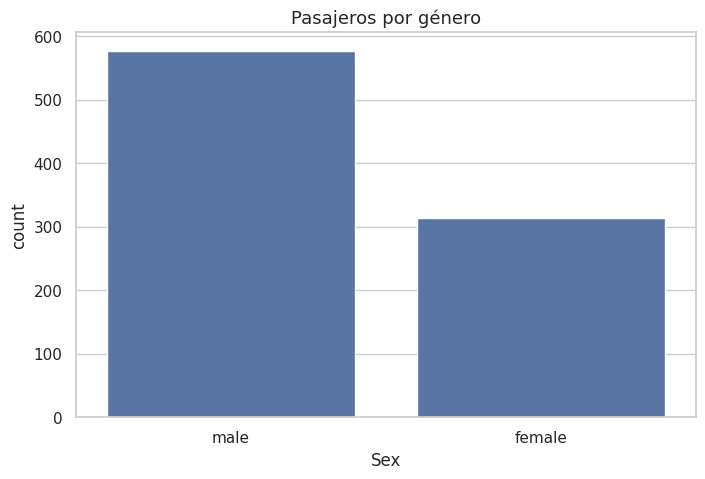

In [11]:
sns.countplot(data=df, x='Sex')
plt.title('Pasajeros por género'); plt.show()

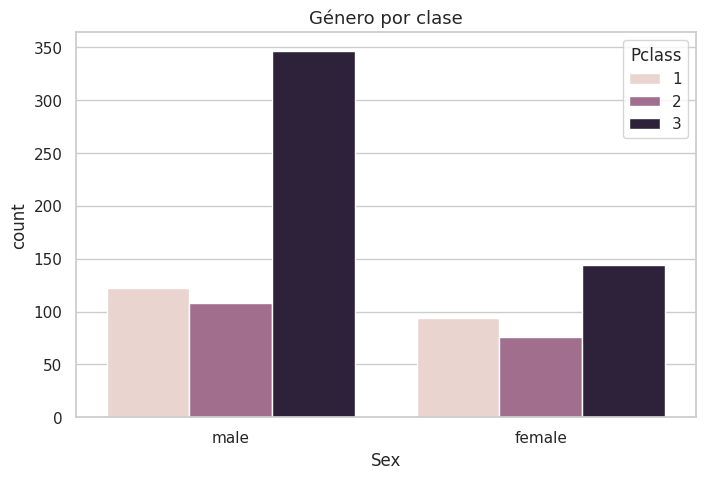

In [12]:
sns.countplot(data=df, x='Sex', hue='Pclass')
plt.title('Género por clase'); plt.show()

In [13]:
pd.crosstab(df['Sex'], df['Pclass'], normalize='columns').round(3)

Pclass,1,2,3
Sex,,,
female,0.435,0.413,0.293
male,0.565,0.587,0.707


In [15]:
df.describe()
df.select_dtypes(exclude='number').describe()

,Name,Sex,Ticket,Cabin,Embarked
count,891,891,891,204,889
unique,891,2,681,147,3
top,"Dooley, Mr. Patrick",male,1601,G6,S
freq,1,577,7,4,644


PassengerId      0
Survived         0
Pclass           0
Name             0
Sex              0
Age            177
SibSp            0
Parch            0
Ticket           0
Fare             0
Cabin          687
Embarked         2
dtype: int64


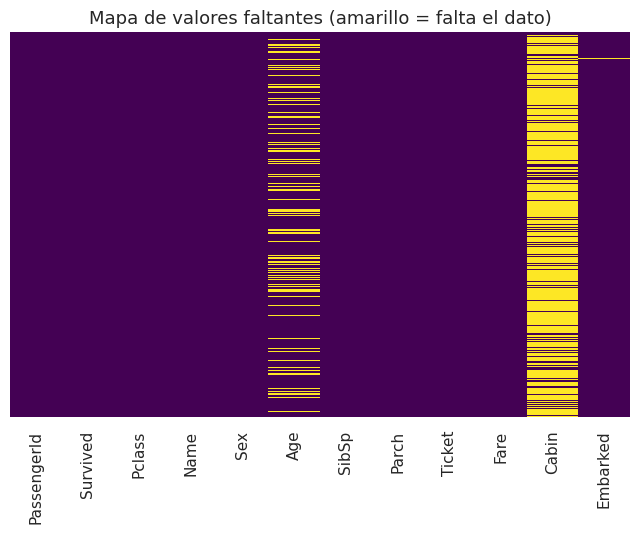

In [16]:
print(df.isnull().sum())
sns.heatmap(df.isnull(), cbar=False, yticklabels=False, cmap='viridis')
plt.title('Mapa de valores faltantes (amarillo = falta el dato)')
plt.show()

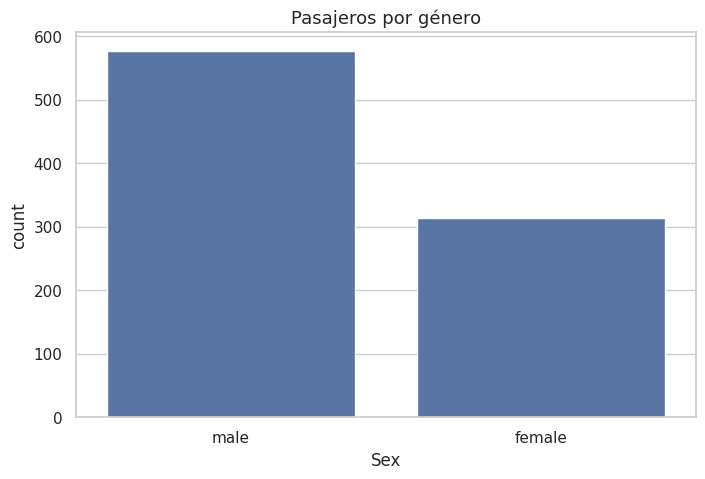

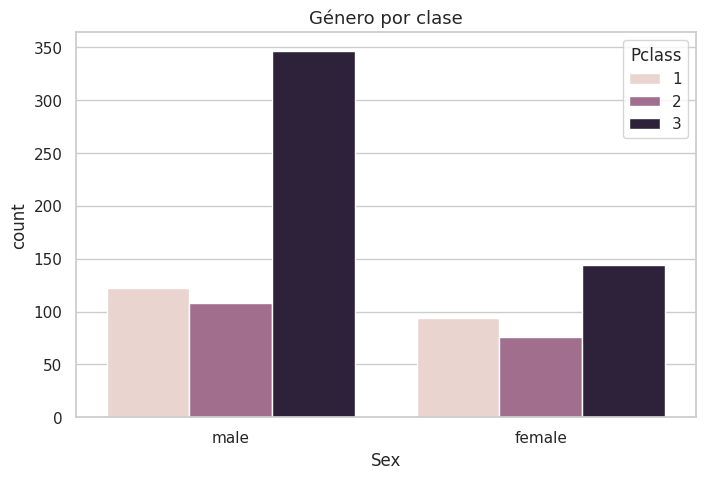

Pclass,1,2,3
Sex,,,
female,0.435,0.413,0.293
male,0.565,0.587,0.707


In [20]:
sns.countplot(data=df, x='Sex')
plt.title('Pasajeros por género'); plt.show()

sns.countplot(data=df, x='Sex', hue='Pclass')
plt.title('Género por clase'); plt.show()

pd.crosstab(df['Sex'], df['Pclass'], normalize='columns').round(3)

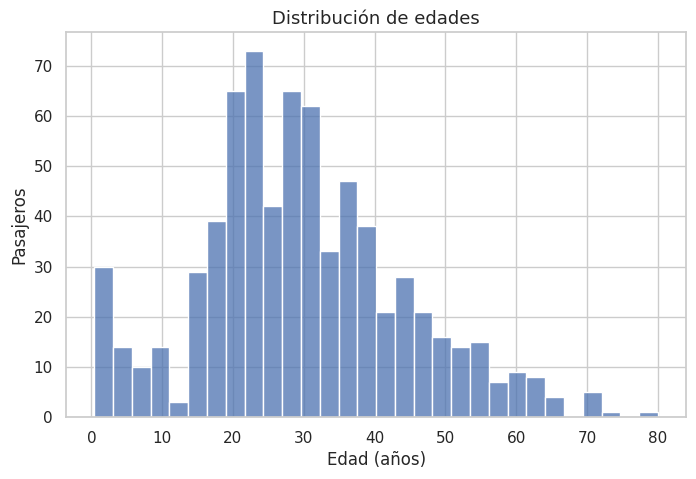

(np.float64(28.0), np.float64(0.42), np.float64(80.0))

In [21]:
sns.histplot(df['Age'].dropna(), bins=30)
plt.title('Distribución de edades'); plt.xlabel('Edad (años)'); plt.ylabel('Pasajeros'); plt.show()
df['Age'].mean()
df['Age'].median(), df['Age'].min(), df['Age'].max()

In [22]:
df['Person'] = np.where(df['Age'] < 16, 'child', df['Sex'])
df['Person'].value_counts()

Person
male      537
female    271
child      83
Name: count, dtype: int64

In [23]:
pd.crosstab(df['Pclass'], df['Person'])

Person,child,female,male
Pclass,,,
1,6,91,119
2,19,66,99
3,58,114,319


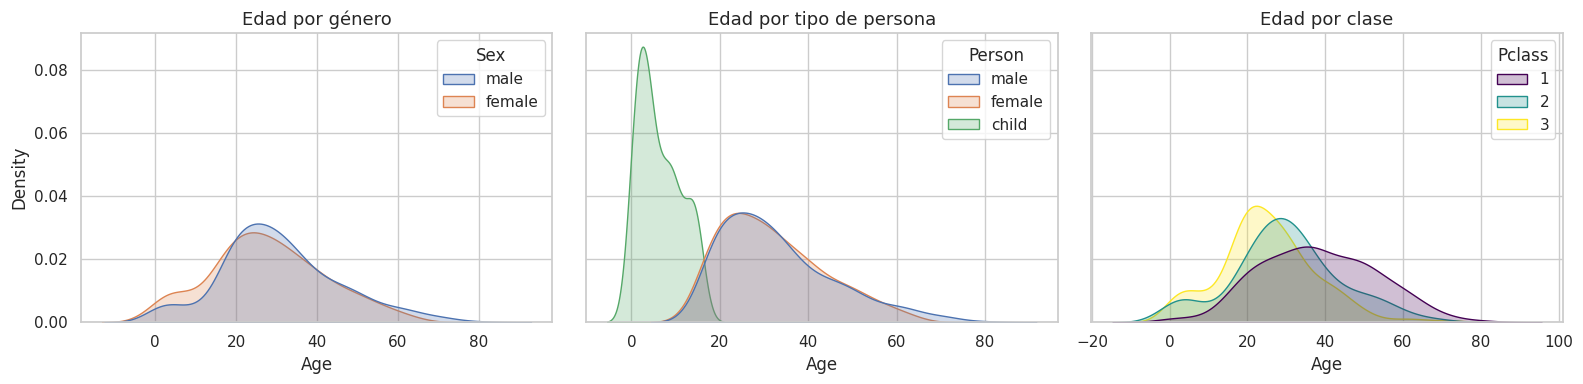

In [24]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4), sharey=True)
sns.kdeplot(data=df, x='Age', hue='Sex', fill=True, common_norm=False, ax=axes[0])
sns.kdeplot(data=df, x='Age', hue='Person', fill=True, common_norm=False, ax=axes[1])
sns.kdeplot(data=df, x='Age', hue='Pclass', fill=True, common_norm=False, palette='viridis', ax=axes[2])
axes[0].set_title('Edad por género')
axes[1].set_title('Edad por tipo de persona')
axes[2].set_title('Edad por clase')
plt.tight_layout(); plt.show()

In [25]:
cabinas = df['Cabin'].dropna()
cubierta = cabinas.str[0]
cubierta.value_counts() 

Cabin
C    59
B    47
D    33
E    32
A    15
F    13
G     4
T     1
Name: count, dtype: int64

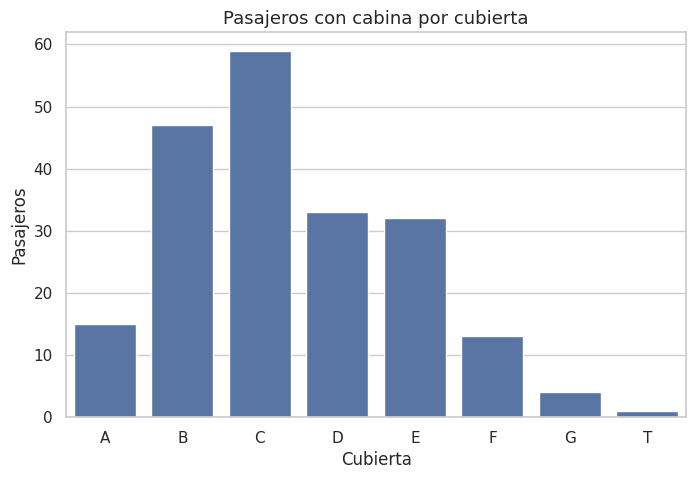

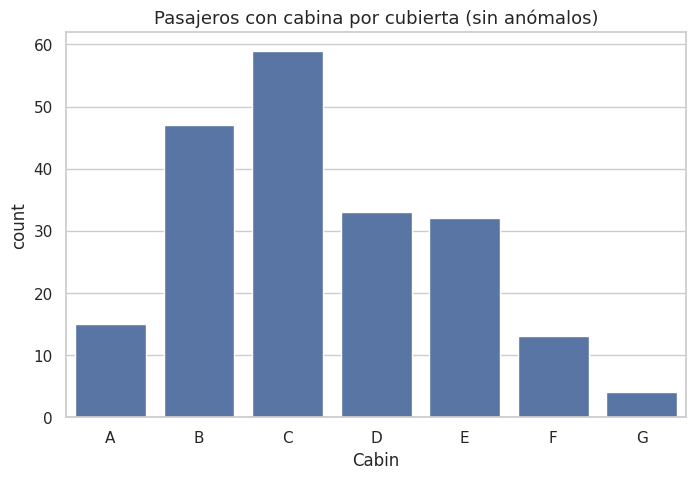

In [26]:
orden = sorted(cubierta.unique())
sns.countplot(x=cubierta, order=orden)
plt.title('Pasajeros con cabina por cubierta'); plt.xlabel('Cubierta'); plt.ylabel('Pasajeros'); plt.show()

# La cubierta 'T' tiene un solo registro (anómalo: el barco no tenía cubierta T de pasajeros normales)
cubierta = cubierta[cubierta != 'T']
sns.countplot(x=cubierta, order=sorted(cubierta.unique()))
plt.title('Pasajeros con cabina por cubierta (sin anómalos)'); plt.show()


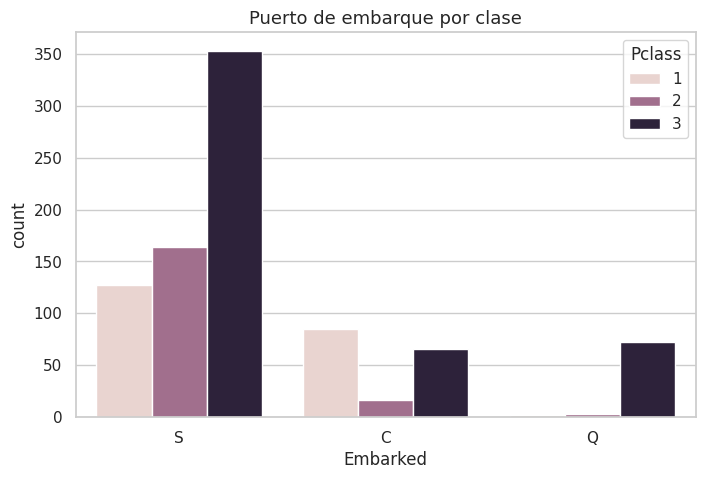

Pclass,1,2,3
Embarked,,,
C,0.506,0.101,0.393
Q,0.026,0.039,0.935
S,0.197,0.255,0.548


In [27]:
sns.countplot(data=df, x='Embarked', hue='Pclass', order=['S', 'C', 'Q'])
plt.title('Puerto de embarque por clase'); plt.show()
pd.crosstab(df['Embarked'], df['Pclass'], normalize='index').round(3)


In [28]:
df['Familia'] = df['SibSp'] + df['Parch']
df['Alone'] = np.where(df['Familia'] > 0, 'with Family', 'Alone')
df['Alone'].value_counts(normalize=True)

Alone
Alone          0.602694
with Family    0.397306
Name: proportion, dtype: float64

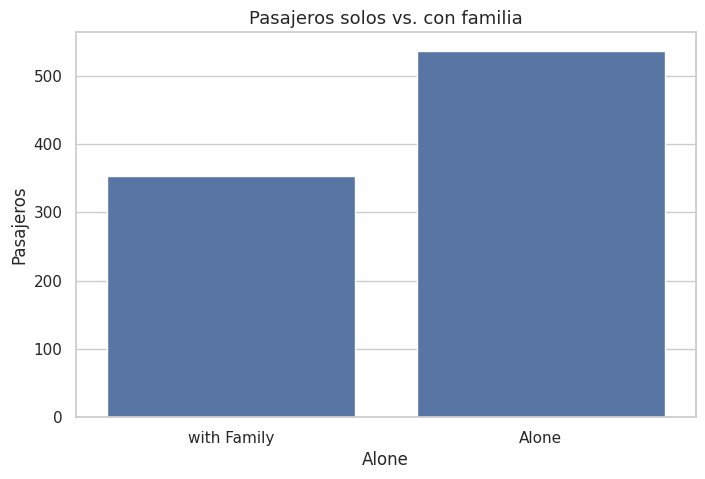

In [29]:
sns.countplot(data=df, x='Alone')
plt.title('Pasajeros solos vs. con familia'); plt.ylabel('Pasajeros'); plt.show()

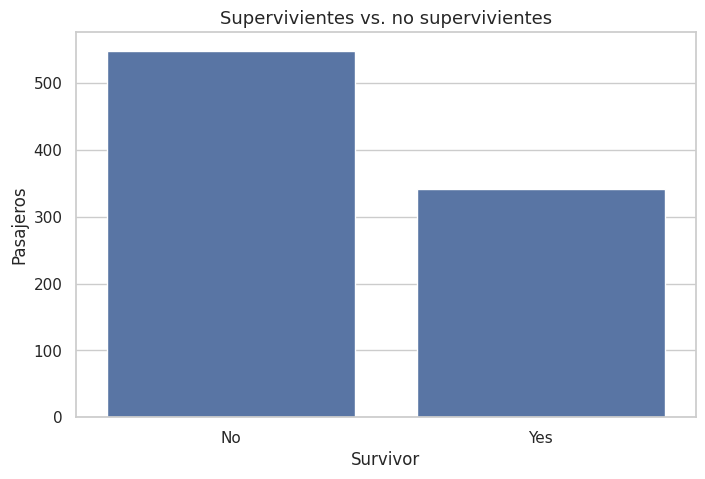

np.float64(0.3838383838383838)

In [30]:
df['Survivor'] = df['Survived'].map({0: 'No', 1: 'Yes'})
sns.countplot(data=df, x='Survivor')
plt.title('Supervivientes vs. no supervivientes'); plt.ylabel('Pasajeros'); plt.show()
df['Survived'].mean() 


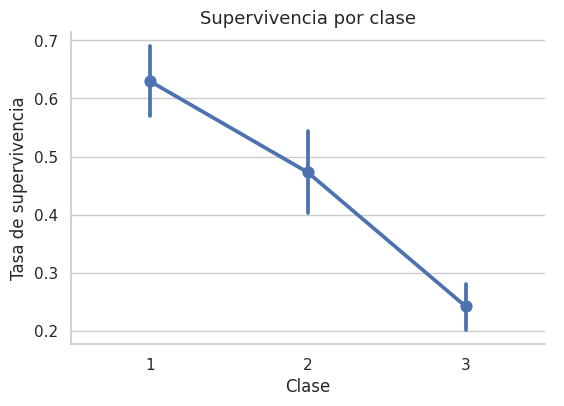

In [31]:
g = sns.catplot(data=df, x='Pclass', y='Survived', kind='point', height=4, aspect=1.4)
g.set_axis_labels('Clase', 'Tasa de supervivencia')
plt.title('Supervivencia por clase'); plt.show()


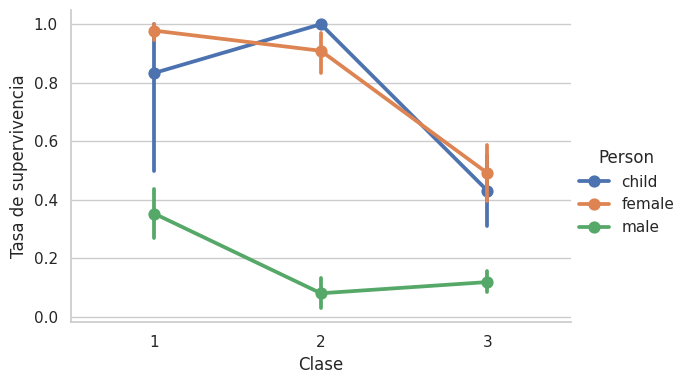

In [32]:
g = sns.catplot(data=df, x='Pclass', y='Survived', hue='Person', kind='point',
                hue_order=['child', 'female', 'male'], height=4, aspect=1.5)
g.set_axis_labels('Clase', 'Tasa de supervivencia')
plt.show()

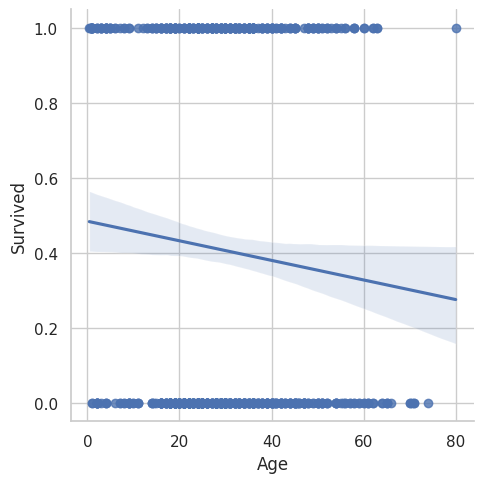

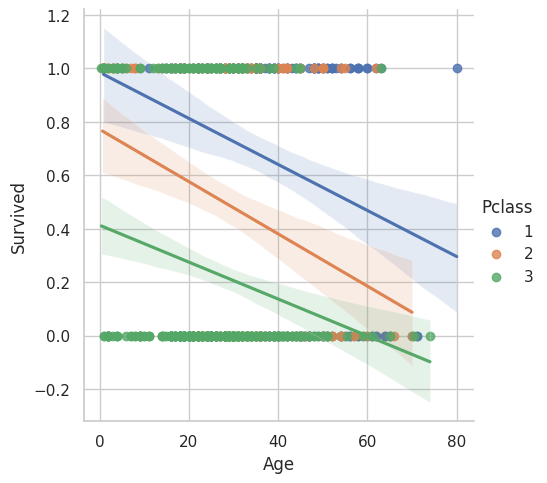

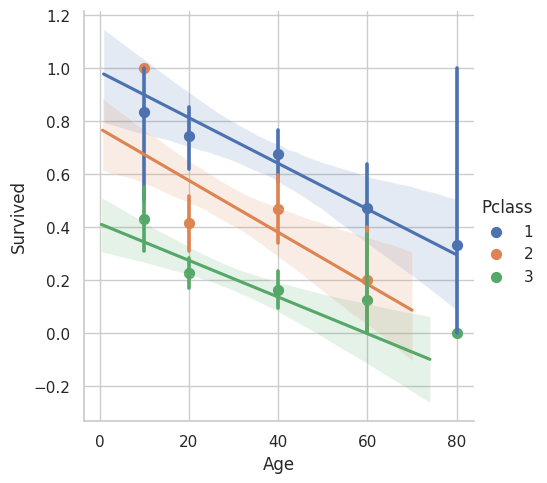

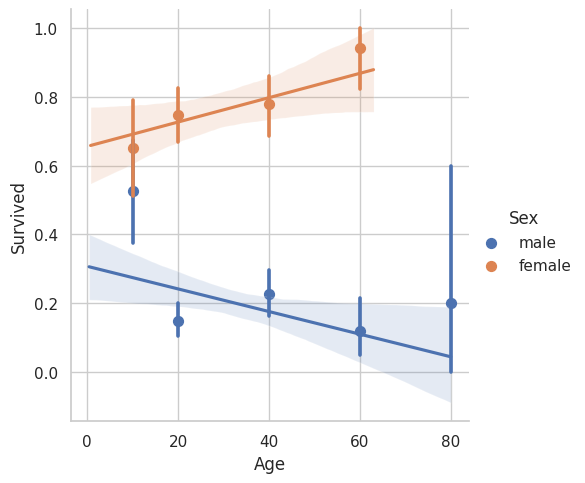

In [33]:
sns.lmplot(data=df, x='Age', y='Survived')
sns.lmplot(data=df, x='Age', y='Survived', hue='Pclass')
generaciones = [10, 20, 40, 60, 80]
sns.lmplot(data=df, x='Age', y='Survived', hue='Pclass', x_bins=generaciones)
sns.lmplot(data=df, x='Age', y='Survived', hue='Sex', x_bins=generaciones)
plt.show()

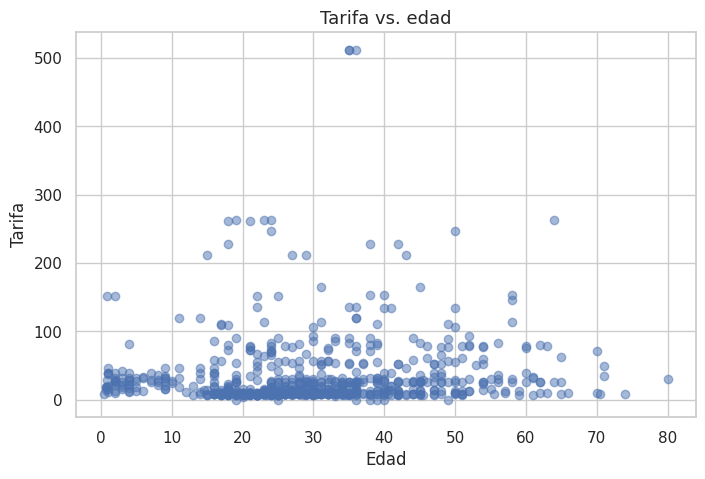

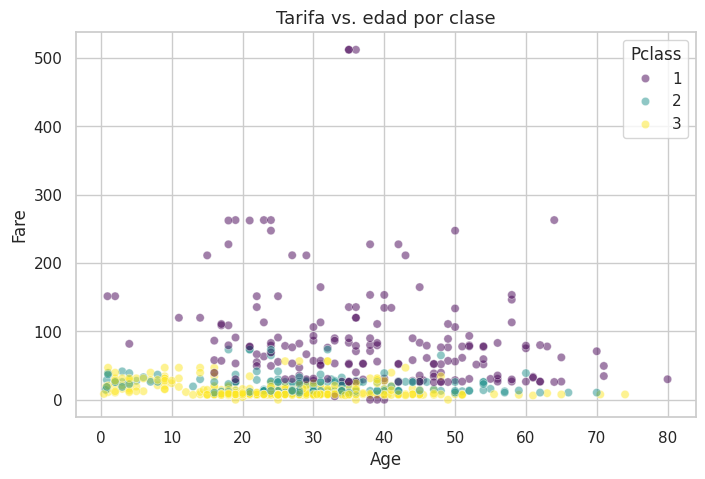

In [34]:
plt.scatter(df['Age'], df['Fare'], alpha=0.5)
plt.xlabel('Edad'); plt.ylabel('Tarifa'); plt.title('Tarifa vs. edad'); plt.show()

sns.scatterplot(data=df, x='Age', y='Fare', hue='Pclass', alpha=0.5, palette='viridis')
plt.title('Tarifa vs. edad por clase'); plt.show()

In [35]:
df['Embarked'].isnull().sum() 
moda = df['Embarked'].mode()[0]
df['Embarked'] = df['Embarked'].fillna(moda)
df['NEmbarked'] = df['Embarked'].map({'S': 0, 'C': 1, 'Q': 2})


In [36]:
std_antes = df['Age'].std() 
promedios = df.groupby('Sex')['Age'].mean()
df['Age'] = df['Age'].fillna(df['Sex'].map(promedios))
df['Age'].isnull().sum()  

np.int64(0)

In [37]:
df['NSex'] = df['Sex'].map({'female': 0, 'male': 1})

In [38]:
df['Cabin'] = df['Cabin'].fillna('X')
df['TCabin'] = df['Cabin'].str[0]
df['TCabin'].value_counts() 
mapa = {letra: i for i, letra in enumerate(sorted(df['TCabin'].unique()))}
df['NCabin'] = df['TCabin'].map(mapa)

In [39]:
df['TTitulo'] = df['Name'].str.extract(r',\s*([^.]+)\.', expand=False).str.strip()
df['TTitulo'].value_counts()  
pd.crosstab(df['TTitulo'], df['Sex'])

Sex,female,male
TTitulo,,
Capt,0,1
Col,0,2
Don,0,1
Dr,1,6
Jonkheer,0,1
Lady,1,0
Major,0,2
Master,0,40
Miss,182,0


In [40]:
reemplazos = {'Master': 'Mr',
              'the Countess': 'Mrs', 'Dona': 'Mrs', 'Mme': 'Mrs',
              'Lady': 'Miss', 'Mlle': 'Miss', 'Ms': 'Miss'}
df['TTitulo'] = df['TTitulo'].replace(reemplazos)
df['TTitulo'] = df['TTitulo'].where(df['TTitulo'].isin(['Mr', 'Mrs', 'Miss']), 'Otro')
df['TTitulo'].value_counts()
df['NTitulo'] = df['TTitulo'].map({'Mr': 0, 'Mrs': 1, 'Miss': 2, 'Otro': 3})

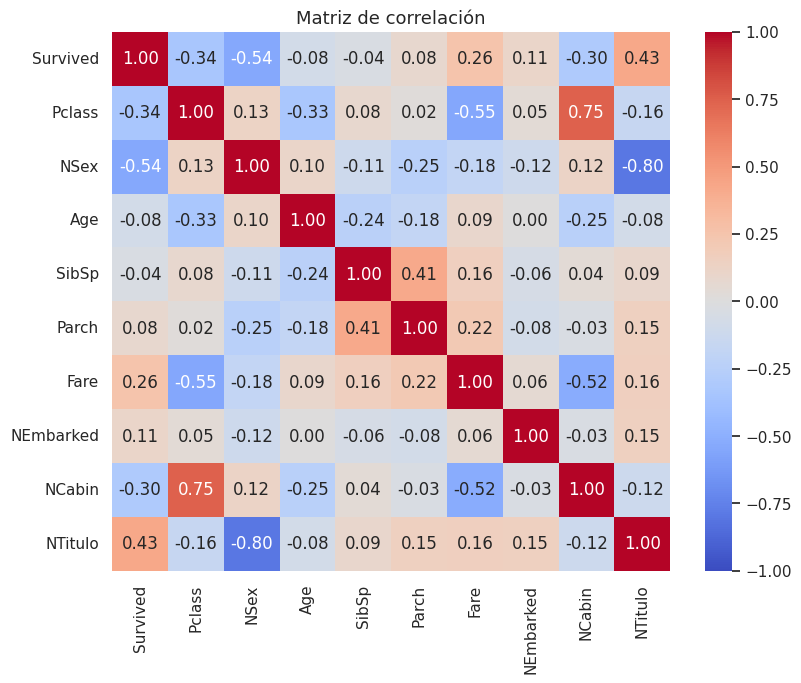

NSex        -0.543351
Pclass      -0.338481
NCabin      -0.301116
Age         -0.080453
SibSp       -0.035322
Parch        0.081629
NEmbarked    0.106811
Fare         0.257307
NTitulo      0.428661
Survived     1.000000
Name: Survived, dtype: float64

In [41]:
cols = ['Survived', 'Pclass', 'NSex', 'Age', 'SibSp', 'Parch', 'Fare', 'NEmbarked', 'NCabin', 'NTitulo']
corr = df[cols].corr()
plt.figure(figsize=(9, 7))
sns.heatmap(corr, annot=True, fmt='.2f', cmap='coolwarm', center=0, vmin=-1, vmax=1)
plt.title('Matriz de correlación'); plt.show()
corr['Survived'].sort_values()


In [42]:
df.groupby('Survived')['Age'].describe()
df.groupby('Sex')['Survived'].agg(['mean', 'sum', 'count'])
df.groupby('Pclass')['Survived'].agg(['mean', 'sum', 'count'])
df.groupby('Alone')['Survived'].agg(['mean', 'sum', 'count'])

,mean,sum,count
Alone,,,
Alone,0.303538,163.0,537
with Family,0.505650,179.0,354


In [43]:
tabla = pd.crosstab(df['Sex'], df['Survived'])
chi2, p, gl, esperados = stats.chi2_contingency(tabla)
print(f'chi2 = {chi2:.1f}, p = {p:.2e}, gl = {gl}')
# p del orden de 1e-58  ->  se rechaza H0: Sex y Survived NO son independientes

chi2 = 260.7, p = 1.20e-58, gl = 1


In [44]:
tabla_c = pd.crosstab(df['Pclass'], df['Survived'])
chi2_c, p_c, gl_c, esp_c = stats.chi2_contingency(tabla_c)
print(f'chi2 = {chi2_c:.1f}, p = {p_c:.2e}') 

chi2 = 102.9, p = 4.55e-23


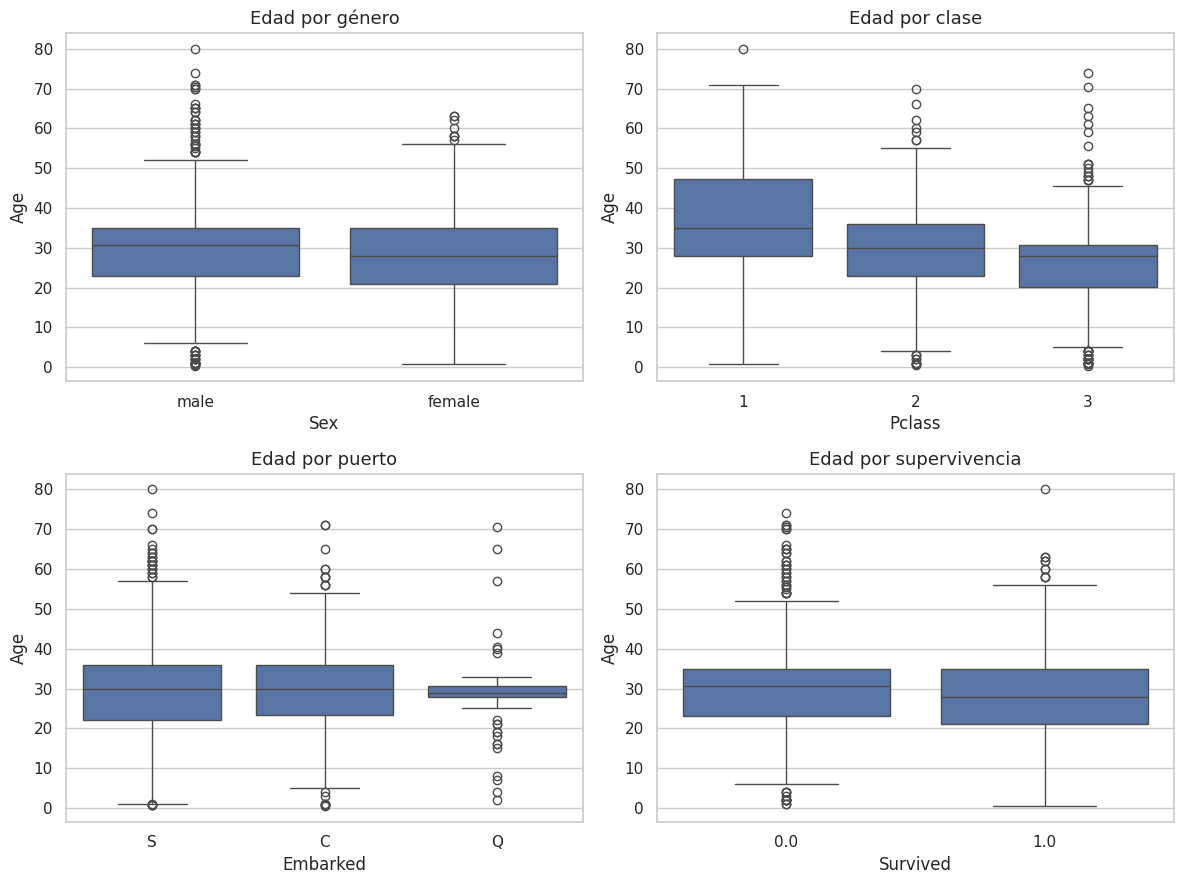

In [45]:
fig, axes = plt.subplots(2, 2, figsize=(12, 9))
sns.boxplot(data=df, x='Sex', y='Age', ax=axes[0, 0])
sns.boxplot(data=df, x='Pclass', y='Age', ax=axes[0, 1])
sns.boxplot(data=df, x='Embarked', y='Age', ax=axes[1, 0])
sns.boxplot(data=df, x='Survived', y='Age', ax=axes[1, 1])
axes[0, 0].set_title('Edad por género'); axes[0, 1].set_title('Edad por clase')
axes[1, 0].set_title('Edad por puerto'); axes[1, 1].set_title('Edad por supervivencia')
plt.tight_layout(); plt.show()


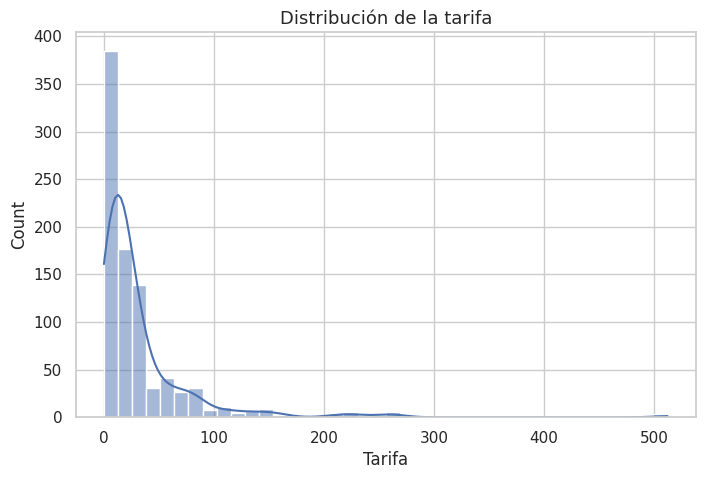

(np.float64(32.204207968574636),
 np.float64(14.4542),
 np.float64(4.787316519674893))

In [46]:
sns.histplot(df['Fare'], kde=True, bins=40)
plt.title('Distribución de la tarifa'); plt.xlabel('Tarifa'); plt.show()
df['Fare'].mean(), df['Fare'].median(), df['Fare'].skew()

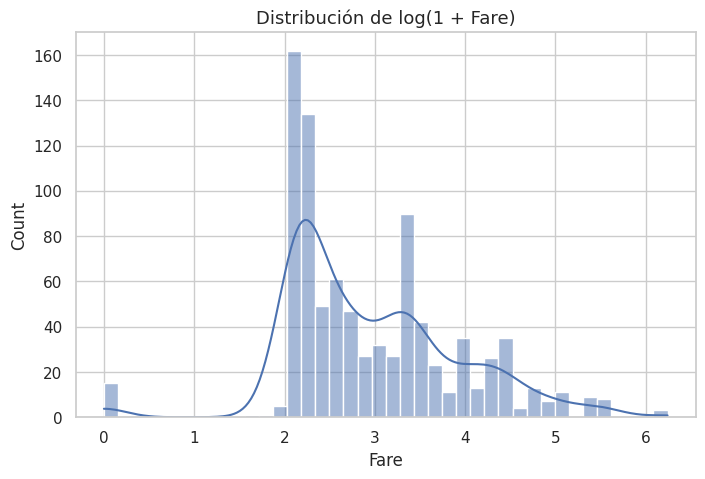

In [47]:
sns.histplot(np.log1p(df['Fare']), kde=True, bins=40)
plt.title('Distribución de log(1 + Fare)'); plt.show()

In [48]:
df_final = df.drop(columns=['Name', 'Sex', 'Embarked', 'Cabin'])


In [49]:
df_final.isnull().sum() 
df_final.dtypes
df_final.info()
df_final.describe()


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 18 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   PassengerId  891 non-null    int64  
 1   Survived     891 non-null    float64
 2   Pclass       891 non-null    int64  
 3   Age          891 non-null    float64
 4   SibSp        891 non-null    int64  
 5   Parch        891 non-null    int64  
 6   Ticket       891 non-null    object 
 7   Fare         891 non-null    float64
 8   Person       891 non-null    object 
 9   Familia      891 non-null    int64  
 10  Alone        891 non-null    object 
 11  Survivor     891 non-null    object 
 12  NEmbarked    891 non-null    int64  
 13  NSex         891 non-null    int64  
 14  TCabin       891 non-null    object 
 15  NCabin       891 non-null    int64  
 16  TTitulo      891 non-null    object 
 17  NTitulo      891 non-null    int64  
dtypes: float64(3), int64(9), object(6)
memory usage: 1

,PassengerId,Survived,Pclass,Age,SibSp,Parch,Fare,Familia,NEmbarked,NSex,NCabin,NTitulo
count,891.000000,891.000000,891.000000,891.000000,891.000000,891.000000,891.000000,891.000000,891.000000,891.000000,891.000000,891.000000
mean,446.000000,0.383838,2.308642,29.736034,0.523008,0.381594,32.204208,0.904602,0.361392,0.647587,6.716049,0.630752
std,257.353842,0.486592,0.836071,13.014897,1.102743,0.806057,49.693429,1.613459,0.635673,0.477990,2.460739,0.890346
min,1.000000,0.000000,1.000000,0.420000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,223.500000,0.000000,2.000000,22.000000,0.000000,0.000000,7.910400,0.000000,0.000000,0.000000,8.000000,0.000000
50%,446.000000,0.000000,3.000000,30.000000,0.000000,0.000000,14.454200,0.000000,0.000000,1.000000,8.000000,0.000000
75%,668.500000,1.000000,3.000000,35.000000,1.000000,0.000000,31.000000,1.000000,1.000000,1.000000,8.000000,1.000000
max,891.000000,1.000000,3.000000,80.000000,8.000000,6.000000,512.329200,10.000000,2.000000,1.000000,8.000000,3.000000


In [50]:
df_final['NAlone'] = df_final['Alone'].map({'with Family': 0, 'Alone': 1})
df_final['NPerson'] = df_final['Person'].map({'child': 0, 'female': 1, 'male': 2})

In [51]:
df.pivot_table(values='Survived', index='Pclass', columns='Sex', aggfunc='mean').round(3)

Sex,female,male
Pclass,,
1,0.968,0.369
2,0.921,0.157
3,0.500,0.135


In [52]:
df.groupby('Embarked')['Survived'].agg(['mean', 'count'])
df.pivot_table(values='Survived', index='Embarked', columns='Pclass', aggfunc='mean').round(2)

Pclass,1,2,3
Embarked,,,
C,0.69,0.53,0.38
Q,0.50,0.67,0.38
S,0.59,0.46,0.19


In [53]:
df['FareQ'] = df.groupby('Pclass')['Fare'].transform(
    lambda s: pd.qcut(s, 4, labels=False, duplicates='drop'))
df.pivot_table(values='Survived', index='FareQ', columns='Pclass', aggfunc='mean').round(2)


Pclass,1,2,3
FareQ,,,
0,0.46,0.35,0.23
1,0.57,0.50,0.20
2,0.75,0.58,0.28
3,0.74,0.59,0.28


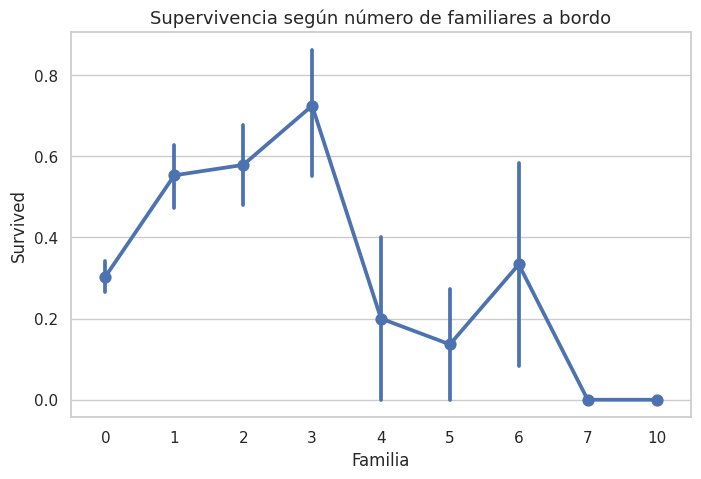

In [54]:
df.groupby('Familia')['Survived'].agg(['mean', 'count'])
sns.pointplot(data=df, x='Familia', y='Survived')
plt.title('Supervivencia según número de familiares a bordo'); plt.show()

In [55]:
def outliers_iqr(serie):
    q1, q3 = serie.quantile([0.25, 0.75])
    iqr = q3 - q1
    return (serie < q1 - 1.5 * iqr) | (serie > q3 + 1.5 * iqr)

for col in ['Fare', 'Age', 'Familia']:
    print(col, outliers_iqr(df[col]).sum())

mask_fare = outliers_iqr(df['Fare'])
df.groupby(mask_fare)['Survived'].agg(['mean', 'count'])
df.nlargest(10, 'Fare')[['Name', 'Pclass', 'Fare', 'Survived']]

tabla_a = pd.crosstab(df['Alone'], df['Survived'])
chi2_a, p_a, gl_a, esp_a = stats.chi2_contingency(tabla_a)
print(f'chi2 = {chi2_a:.1f}, p = {p_a:.2e}')

Fare 116
Age 66
Familia 91
chi2 = 36.0, p = 1.97e-09
